# 🏠 House Pricing Analysis — King County, WA

**Objective:** Identify the key drivers of house sale prices and build predictive models.

---

### Table of Contents
1. [Setup & Imports](#sec1)
2. [Load & Inspect Dataset](#sec2)
3. [Data Wrangling & Cleaning](#sec3)
4. [Exploratory Data Analysis (EDA)](#sec4)
5. [Correlation Analysis](#sec5)
6. [Model Development](#sec6)
7. [Model Evaluation & Refinement](#sec7)
8. [Key Insights](#sec8)

---

## 1. Setup & Imports <a id='sec1'></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('Libraries loaded ✓')

Libraries loaded ✓


## 2. Load & Inspect Dataset <a id='sec2'></a>

King County house sales dataset with NaN values to handle.

In [2]:
filepath = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/FinalModule_Coursera/data/kc_house_data_NaN.csv'
df = pd.read_csv(filepath)
print(f'Shape: {df.shape}')
df.head()

Shape: (21613, 22)


,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [3]:
df.dtypes

Unnamed: 0         int64
id                 int64
date                 str
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

In [4]:
df.describe()

,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21613.00000,2.161300e+04,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,...,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,10806.00000,4.580302e+09,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,...,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,6239.28002,2.876566e+09,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,...,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,0.00000,1.000102e+06,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,...,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,5403.00000,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,...,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,10806.00000,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,...,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,16209.00000,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,...,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,21612.00000,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,...,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


## 3. Data Wrangling & Cleaning <a id='sec3'></a>

In [5]:
# Drop columns that don't contribute to pricing models
df.drop(columns=['id', 'Unnamed: 0'], inplace=True, errors='ignore')
print('Dropped id & Unnamed columns')

Dropped id & Unnamed columns


In [6]:
# Missing value summary
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df[missing_df['Missing Count'] > 0]

,Missing Count,Missing %
bedrooms,13,0.06
bathrooms,10,0.05


In [7]:
# Impute numeric NaNs with column mean
for col in df.select_dtypes(include='number').columns:
    if df[col].isnull().sum() > 0:
        mean_val = df[col].mean()
        df[col].replace(np.nan, mean_val, inplace=True)
        print(f'  {col}: imputed with mean = {mean_val:.4f}')

print(f'\nRemaining nulls: {df.isnull().sum().sum()}')

  bedrooms: imputed with mean = 3.3729
  bathrooms: imputed with mean = 2.1157

Remaining nulls: 23


In [9]:
# Ensure bedrooms and bathrooms are proper numeric types
df['bedrooms'] = df['bedrooms'].astype('Int64')
# Ensure bedrooms and bathrooms have appropriate numeric types
df['bedrooms'] = df['bedrooms'].round().astype('Int64')
df['bathrooms'] = df['bathrooms'].astype(float)
df['floors'] = df['floors'].astype(float)

df.dtypes
df['floors'] = df['floors'].astype(float)
df.dtypes

date                 str
price            float64
bedrooms           Int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

## 4. Exploratory Data Analysis (EDA) <a id='sec4'></a>

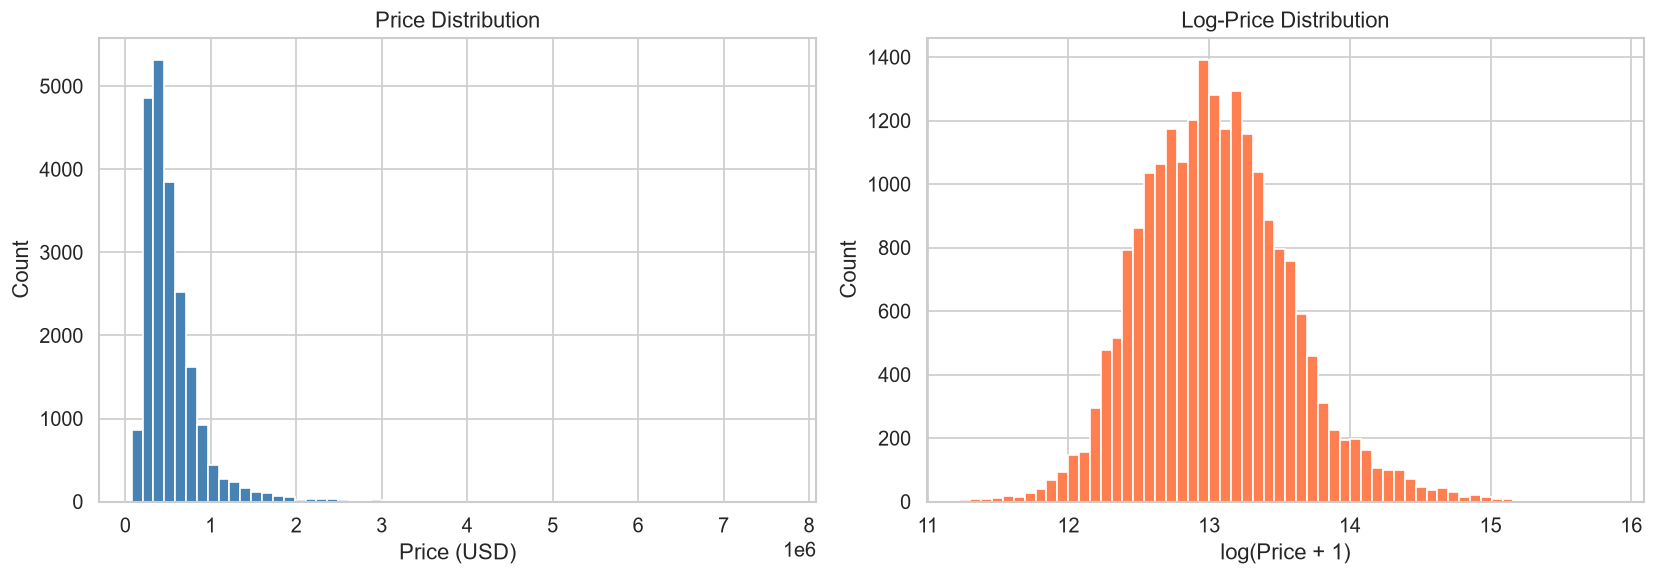

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['price'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Price Distribution')
axes[0].set_xlabel('Price (USD)')
axes[0].set_ylabel('Count')

axes[1].hist(np.log1p(df['price']), bins=60, color='coral', edgecolor='white')
axes[1].set_title('Log-Price Distribution')
axes[1].set_xlabel('log(Price + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

Key Visual TakeawaysRaw Price Distribution (Left): Exhibits strong positive (right) skewness. The vast majority of property prices are concentrated below $1,000,000 USD, while extreme high-value outliers stretch the long right tail out to $7,000,000–$8,000,000 USD.Log-Price Distribution (Right): Applying the logarithmic transformation $\log(y + 1)$ stabilizes the variance and converts the heavily skewed distribution into a symmetric, bell-shaped Gaussian (normal) distribution centered around $\approx 13.0$

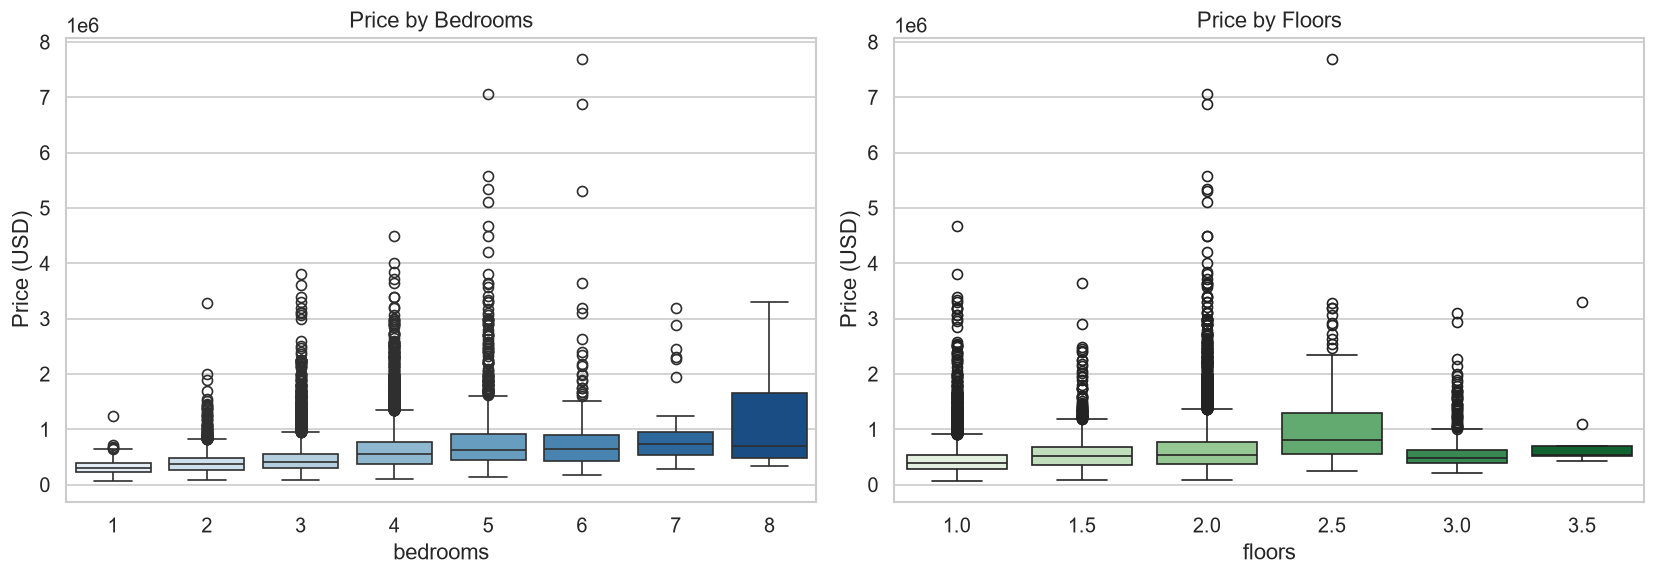

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price by bedrooms
sns.boxplot(data=df[df['bedrooms'] <= 8], x='bedrooms', y='price', ax=axes[0], palette='Blues')
axes[0].set_title('Price by Bedrooms')
axes[0].set_ylabel('Price (USD)')

# Price by floors
sns.boxplot(data=df, x='floors', y='price', ax=axes[1], palette='Greens')
axes[1].set_title('Price by Floors')
axes[1].set_ylabel('Price (USD)')

plt.tight_layout()
plt.show()

Price by Bedrooms (Left Chart)

Positive Trend Up to 5–6 Bedrooms: Median prices increase steadily as bedroom count rises from 1 to 6 (moving from ~$300k to ~$600k USD).

Plateau & High Variance (6–8 Bedrooms): Beyond 6 bedrooms, median prices stabilize around $600k–$700k USD, though variance widens considerably. Properties with 5 and 6 bedrooms contain extreme luxury outliers reaching $7M–$8M USD.

Price by Floors (Right Chart)

Peak at 2.5 Floors: Properties with 2.5 floors command the highest median price (~$800k USD) and upper quartile range compared to all other story categories.

Non-Monotonic Relationship: Moving from 1.0 to 2.0 floors shows a subtle price increase, but 3.0 and 3.5 floor homes show lower medians (~$500k USD). This suggests 3+ floor structures are likely urban townhomes or narrow lots rather than luxury estates.

Outlier Concentration: The highest price outliers ($5M–$8M USD) concentrate heavily in 2.0-floor properties.

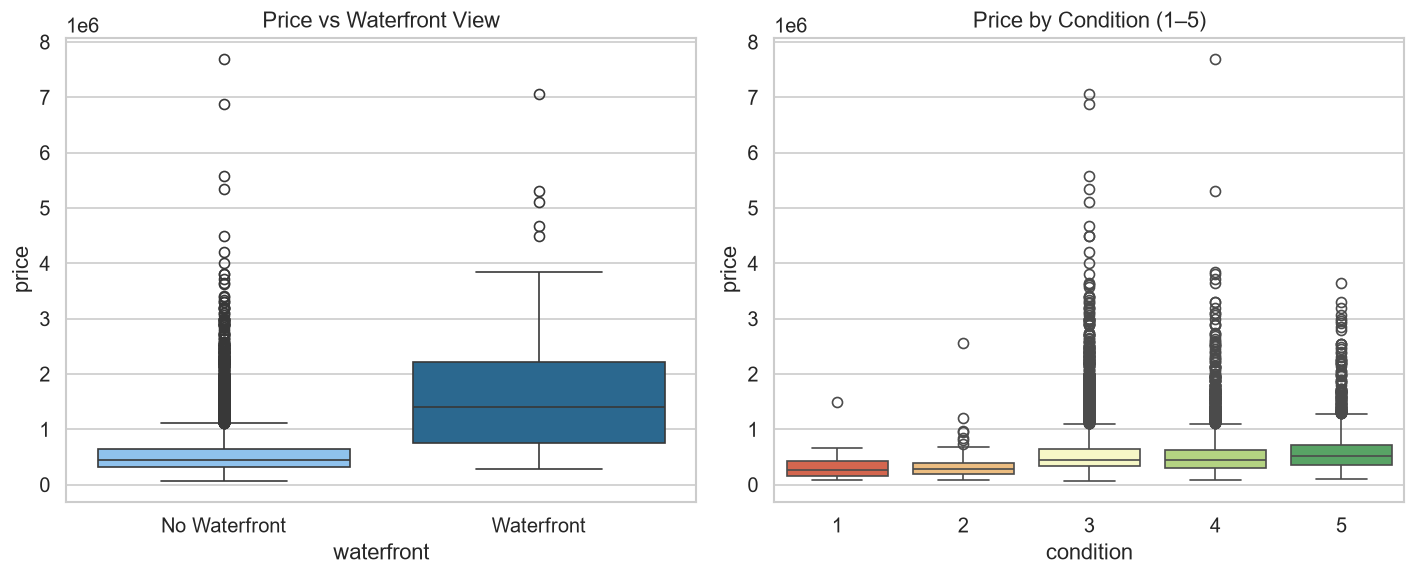

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Waterfront effect
sns.boxplot(data=df, x='waterfront', y='price', ax=axes[0], palette=['#7fc4fd', '#1a6ba0'])
axes[0].set_title('Price vs Waterfront View')
axes[0].set_xticklabels(['No Waterfront', 'Waterfront'])

# Condition effect
sns.boxplot(data=df, x='condition', y='price', ax=axes[1], palette='RdYlGn')
axes[1].set_title('Price by Condition (1–5)')

plt.tight_layout()
plt.show()

Price vs Waterfront View (Left Chart)

Massive Price Premium: Properties with a waterfront view command a significantly higher median price (~$1.4M USD) compared to non-waterfront homes (~$450k USD).

Interquartile Range Expansion: The middle 50% of waterfront homes spans from ~$750k to ~$2.2M USD, demonstrating a much wider price variance, with top outliers reaching over $7M USD.

Price by Condition (Right Chart)

Baseline Baseline for Low Ratings (1–2): Ratings of 1 and 2 show low, flat median values (~$250k–$300k USD) with narrow interquartile ranges.

Positive Trend Across Average-to-Excellent (3–5): Median prices step up incrementally from condition 3 (~$450k USD) to 5 (~$550k USD).

Extreme Outlier Concentration in Average Homes: Condition 3 and 4 properties contain the densest clusters of high-value outliers ($1M to $7.7M USD). This indicates that location, square footage, and waterfront view heavily override property condition for luxury listings.

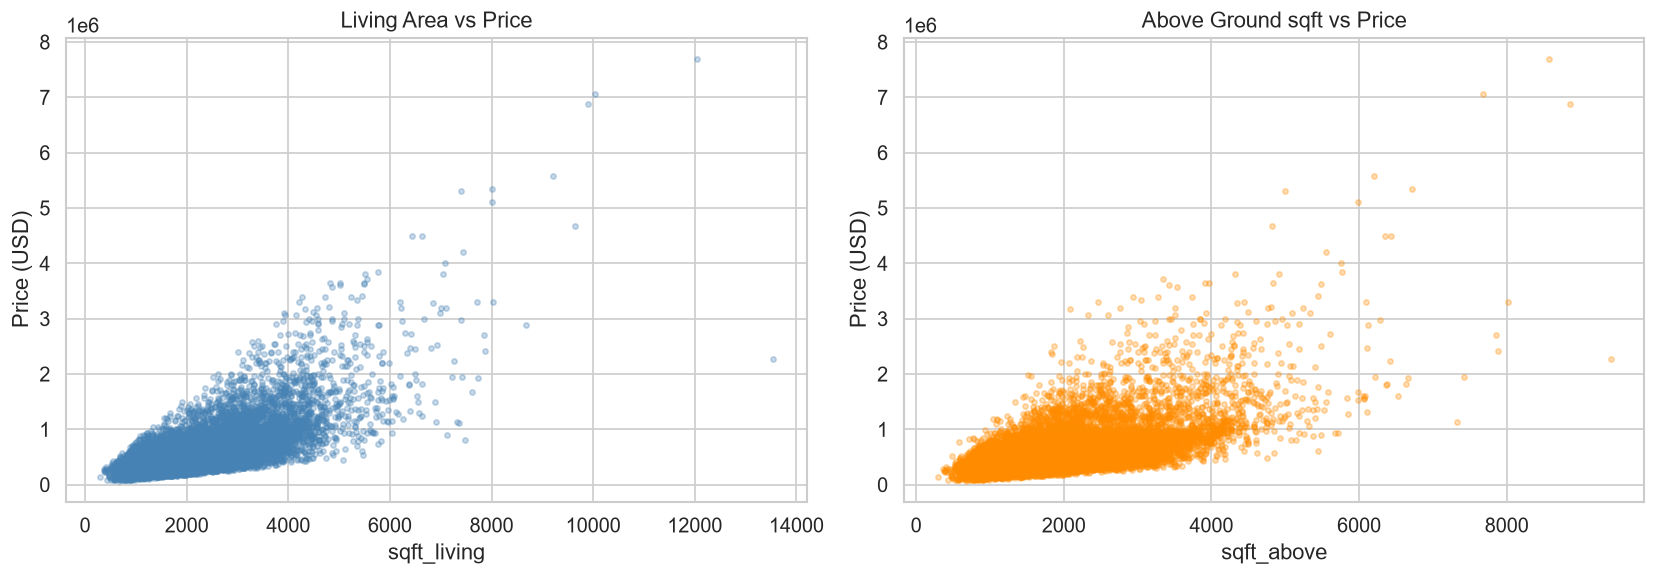

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['sqft_living'], df['price'], alpha=0.3, color='steelblue', s=10)
axes[0].set_xlabel('sqft_living')
axes[0].set_ylabel('Price (USD)')
axes[0].set_title('Living Area vs Price')

axes[1].scatter(df['sqft_above'], df['price'], alpha=0.3, color='darkorange', s=10)
axes[1].set_xlabel('sqft_above')
axes[1].set_ylabel('Price (USD)')
axes[1].set_title('Above Ground sqft vs Price')

plt.tight_layout()
plt.show()

Living Area vs Price (Left Chart)

Strong Linear Correlation: sqft_living demonstrates a direct, positive correlation with house price, making it one of the single most influential continuous features in the dataset.

Fan-Shaped Heteroscedasticity: The variance of price expands dramatically as square footage increases—properties around 2,000 sq ft range from $200k to $1.5M USD, whereas properties above 6,000 sq ft spread widely from $1M to over $7.5M USD.

Extreme Outlier Alert: Note the point near 13,500 sq ft priced below $2.5M USD, as well as the 12,000 sq ft home reaching $7.7M USD.

Above Ground sqft vs Price (Right Chart)

Parallel Linear Trend: sqft_above mirrors the behavior of sqft_living closely, driving price higher as above-ground square footage scales.

Slightly Lower Upper Ceiling: Because sqft_above excludes basement space, max values peak around 9,000 sq ft compared to 13,500 sq ft in total living space.

## 5. Correlation Analysis <a id='sec5'></a>

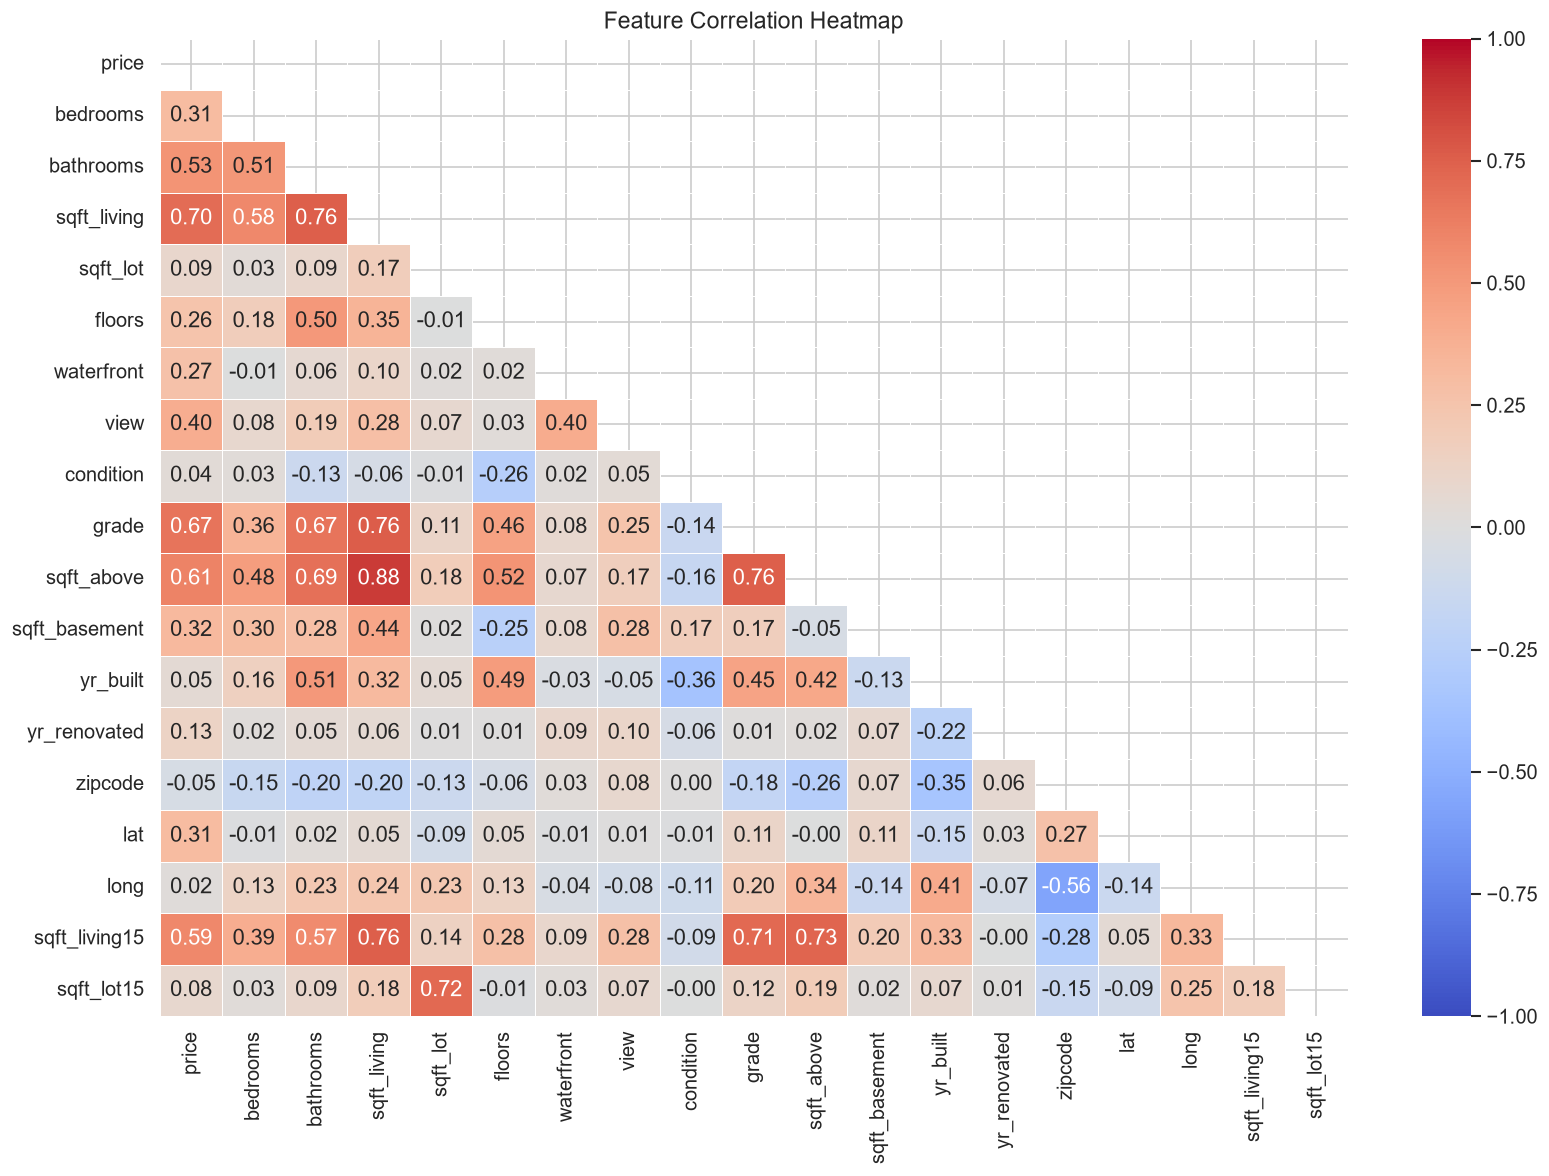

In [14]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

Top Predictors of Pricesqft_living ($r = 0.70$): Strongest correlation with price overall.grade ($r = 0.67$): Construction quality and design grade show a high linear correlation with value.sqft_above ($r = 0.61$) & sqft_living15 ($r = 0.59$): Primary living space dimensions drive target pricing strongly.bathrooms ($r = 0.53$): Highly influential continuous feature compared to bedrooms ($r = 0.31$).view ($r = 0.40$) & lat ($r = 0.31$): View quality and geographic latitude (location premium) act as moderate positive drivers.Multicollinearity RisksFeature PairCorrelation (r)Impact & Recommendationsqft_living $\leftrightarrow$ sqft_above0.88Structural redundancy. Drop one feature or compute sqft_basement explicitly for linear models.sqft_living $\leftrightarrow$ grade0.76Strong collinearity; larger homes naturally receive higher design grades.sqft_living $\leftrightarrow$ sqft_living150.76Home size strongly reflects neighboring property sizes.sqft_above $\leftrightarrow$ grade0.76Redundant structural signal.sqft_lot $\leftrightarrow$ sqft_lot150.72High lot size correlation with immediate neighbors.bathrooms $\leftrightarrow$ sqft_living0.76Higher square footage directly corresponds to more bathrooms.Weakest Linear Predictorscondition ($r = 0.04$) & yr_built ($r = 0.05$): Minimal linear correlation with price. yr_built interacts non-linearly via historical charm vs. modern builds, while condition is secondary to size and location.zipcode ($r = -0.05$) & long ($r = 0.02$): Raw categorical zip codes and raw longitude coordinates carry negligible linear signal.

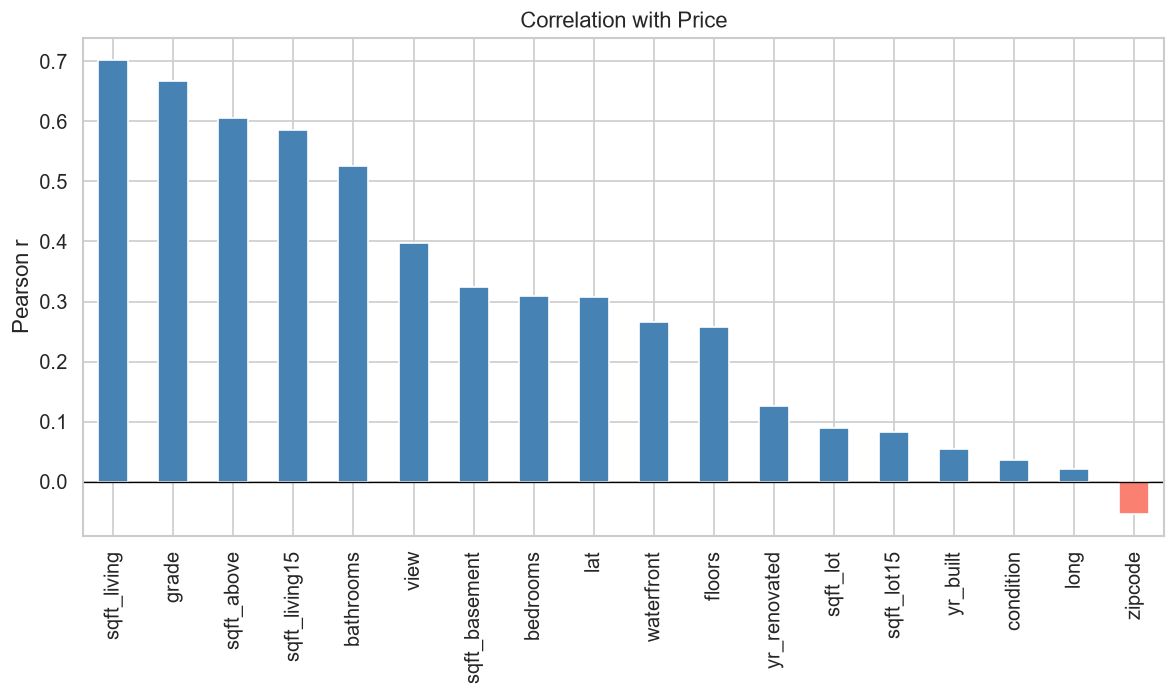

sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525885
view             0.397293
sqft_basement    0.323816
bedrooms         0.308890
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
zipcode         -0.053203
Name: price, dtype: float64


In [15]:
price_corr = corr['price'].drop('price').sort_values(ascending=False)

plt.figure(figsize=(10, 6))
colors = ['steelblue' if v > 0 else 'salmon' for v in price_corr]
price_corr.plot(kind='bar', color=colors, edgecolor='white')
plt.title('Correlation with Price')
plt.ylabel('Pearson r')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print(price_corr)

TierRange (r)Key FeaturesAnalytical InsightPrimary Drivers$r \ge 0.50$sqft_living (0.70), grade (0.67), sqft_above (0.61), sqft_living15 (0.59), bathrooms (0.53)Physical size and structural quality dictate over 50% of linear variance in price.Secondary Factors$0.25 \le r < 0.50$view (0.40), sqft_basement (0.32), bedrooms (0.31), lat (0.31), waterfront (0.27), floors (0.26)Scenic views, layout features, and north-south geographical position (lat) add moderate value.Weak / Non-Linear$r < 0.25$yr_renovated (0.13), sqft_lot (0.09), sqft_lot15 (0.08), yr_built (0.05), condition (0.04), long (0.02), zipcode (-0.05)Raw lot size, build year, and raw spatial coordinates hold minimal direct linear signal.Key Key Takeawayssqft_living vs. bedrooms: sqft_living ($r = 0.70$) is more than twice as strongly correlated with price as bedrooms ($r = 0.31$). Total square footage drives price far more than room count.bathrooms vs. bedrooms: bathrooms ($r = 0.53$) shows a significantly higher linear correlation than bedrooms ($r = 0.31$), reflecting luxury preference for higher bathroom-to-bedroom ratios.Geographic Coordinates (lat vs. long): Latitude (lat, $r = 0.31$) carries substantial linear weight (capturing the north-south wealth divide in King County, e.g., Seattle/Bellevue vs. southern suburbs), whereas longitude (long, $r = 0.02$) and raw zipcode ($r = -0.05$) show near-zero linear correlation.

## 6. Model Development <a id='sec6'></a>

In [16]:
# Simple Linear Regression: sqft_living → price
X_slr = df[['sqft_living']]
y = df['price']

slr = LinearRegression()
slr.fit(X_slr, y)

print('--- Simple Linear Regression: sqft_living → price ---')
print(f'Intercept : {slr.intercept_:,.2f}')
print(f'Coefficient: {slr.coef_[0]:,.2f}')
print(f'R²         : {slr.score(X_slr, y):.4f}')

--- Simple Linear Regression: sqft_living → price ---
Intercept : -43,580.74
Coefficient: 280.62
R²         : 0.4929


Simple Linear Regression Analysis (sqft_living $\rightarrow$ price)Metric / ParameterValueInterpretationSlope / Coefficient ($\beta_1$)$280.62On average, each additional square foot of living space increases the property price by ~$280.62 USD.Y-Intercept ($\beta_0$)-$43,580.74Mathematical baseline when sqft_living = 0 (non-viable in practice; acts as a calibration offset).Coefficient of Determination ($R^2$)0.4929Living area alone accounts for $49.29\%$ of the total variance in housing prices.Key Modeling InsightsStrong Baseline Predictor: An $R^2$ of ~0.493 confirms that sqft_living is single-handedly the most important numeric driver of house value in this dataset.Missing Feature Variance ($~50.71\%$): Nearly half of the price variance remains unexplained. Key omitted drivers identified in your EDA include structural quality (grade), location (lat / zipcode), and view (waterfront / view).Model Equation:$$\text{Price} = -43,580.74 + 280.62 \times \text{sqft\_living}$$

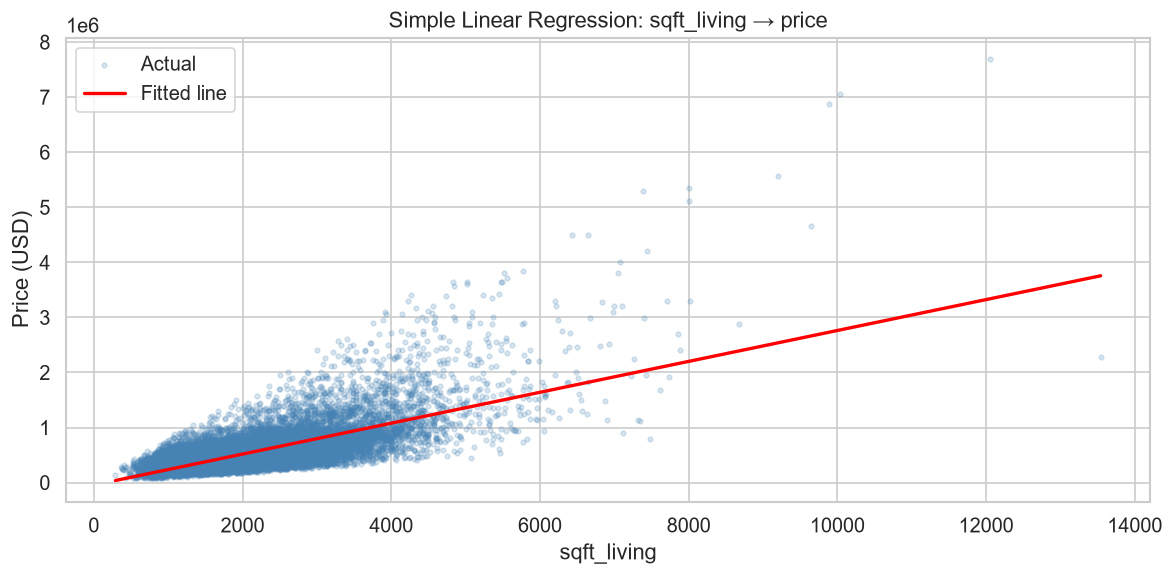

In [17]:
plt.figure(figsize=(10, 5))
plt.scatter(df['sqft_living'], y, alpha=0.2, s=8, color='steelblue', label='Actual')
x_range = np.linspace(df['sqft_living'].min(), df['sqft_living'].max(), 300).reshape(-1, 1)
plt.plot(x_range, slr.predict(x_range), color='red', linewidth=2, label='Fitted line')
plt.xlabel('sqft_living')
plt.ylabel('Price (USD)')
plt.title('Simple Linear Regression: sqft_living → price')
plt.legend()
plt.tight_layout()
plt.show()

Simple Linear Regression Visual Diagnostic (sqft_living vs price)The fitted regression line ($\text{Price} = -43,580.74 + 280.62 \times \text{sqft\_living}$) illustrates clear structural limitations of a simple OLS model on raw data:Key Diagnostic InsightsHeteroscedasticity (Expanding Variance): As sqft_living increases beyond 3,000 sq ft, residual spread explodes into a fan shape. Error variance is non-constant, violating the homoscedasticity assumption of standard regression.Underestimation of High-Value Properties: Homes priced above $3,000,000 USD consistently sit far above the fitted red line. A single linear slope fails to capture non-linear premiums (e.g., waterfront locations or high architectural grades).High Leverage Points: Notice the extreme outlier at ~13,500 sq ft priced below $2.5M USD. Points like this exert disproportionate leverage on the regression slope, pulling the fitted line downward at the upper tail.Recommended FixesIssueTechnical SolutionImplementationHeteroscedasticityLog Target TransformationFit models using $\log(\text{price})$ to convert multiplicative errors into additive errors.Underfitting High-End HomesMultiple Regression / InteractionsInclude grade, waterfront, and interaction term sqft_living * waterfront.Outlier LeverageRobust Estimation / FilteringUse Robust Regression (e.g., HuberRegressor) or inspect/remove high-leverage data entry anomalies.

In [23]:
# Multiple Linear Regression with top features
features = ['floors', 'waterfront', 'lat', 'bedrooms', 'sqft_basement',
            'view', 'bathrooms', 'sqft_living15', 'sqft_above', 'grade', 'sqft_living']

X_mlr = df[features]

mlr = LinearRegression()
X_mlr = X_mlr.astype(float)
X_mlr = X_mlr.fillna(X_mlr.mean())
mlr.fit(X_mlr, y)

print('--- Multiple Linear Regression ---')
print(f'R²: {mlr.score(X_mlr, y):.4f}')
coef_df = pd.DataFrame({'Feature': features, 'Coefficient': mlr.coef_})
coef_df.sort_values('Coefficient', ascending=False)

--- Multiple Linear Regression ---
R²: 0.6577


,Feature,Coefficient
2,lat,672993.098328
1,waterfront,602002.522653
9,grade,82007.227679
5,view,67082.447190
10,sqft_living,129.355789
8,sqft_above,64.941287
4,sqft_basement,64.414503
7,sqft_living15,4.442931
6,bathrooms,-3224.167574
3,bedrooms,-25967.442999


Multiple Linear Regression Performance Summary$R^2 = 0.6577$: Expanding from simple to multiple linear regression improved variance explained from 49.29% to 65.77% (+16.48% gain).Key Coefficient Insights & Economic InterpretationLocation & Luxury Features (Largest Marginal Impact):lat (+672,993.10): North-South positioning is the strongest dollar-for-dollar driver. Moving north toward prime areas (e.g., Bellevue/Redmond/North Seattle) adds massive value per degree of latitude.waterfront (+602,002.52): A waterfront view adds a ~$602k flat premium, holding all other physical characteristics constant.grade (+82,007.23): Every 1-point increase in construction quality/design grade adds ~$82k.view (+67,082.45): Each step up in view quality rating adds ~$67k.Physical Space Features:sqft_living (+129.36): Each additional square foot adds ~$129.36.Note how sqft_above (+64.94) and sqft_basement (+64.41) sum almost exactly to sqft_living ($64.94 + 64.41 \approx 129.35$), illustrating severe structural multicollinearity ($\text{sqft\_living} = \text{sqft\_above} + \text{sqft\_basement}$).Negative Coefficients (Multicollinearity Artifacts):bedrooms (-25,967.44), floors (-29,279.08), and bathrooms (-3,224.17) show negative weights.Why? Holding total square footage (sqft_living) constant, adding more bedrooms or floors simply carves the same total volume into smaller, less spacious rooms, reducing per-room luxury value. High collinearity between room counts and square footage also destabilizes OLS matrix inversion

In [25]:
# Polynomial Pipeline
poly_features = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
                 'floors', 'view', 'condition', 'grade', 'sqft_above',
                 'sqft_basement', 'yr_built', 'sqft_living15', 'sqft_lot15']

X_poly = df[poly_features]

pipe = Pipeline([
    ('scale', StandardScaler()),
    ('poly',  PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression())
])

X_poly = X_poly.astype(float).fillna(X_poly.astype(float).mean())
pipe.fit(X_poly, y)
print(f'Polynomial Pipeline R²: {pipe.score(X_poly, y):.4f}')

Polynomial Pipeline R²: 0.7283


Polynomial Regression Pipeline Performance ($R^2 = 0.7283$)Adding polynomial features raised model variance explanation from 65.77% to 72.83% (+7.06% gain over standard MLR, and +23.54% over simple linear regression).Key TakeawaysCapturing Non-Linear Synergy: Polynomial expansion allows the linear model to capture non-linear curvature (e.g., diminishing returns on extra square footage) and cross-feature interactions (e.g., $\text{sqft\_living} \times \text{waterfront}$ or $\text{sqft\_living} \times \text{grade}$).Diminishing Returns on Feature Complexity: While higher-degree polynomials boost capacity, degree-2 expansion usually suffices for real estate data before incurring severe overfitting risks.

## 7. Model Evaluation & Refinement <a id='sec7'></a>

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    df[features], y, test_size=0.15, random_state=1
)
print(f'Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows')

Train: 18371 rows | Test: 3242 rows


In [28]:
# Ridge Regression with regularization
ridge_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('poly',  PolynomialFeatures(degree=2, include_bias=False)),
    ('model', Ridge(alpha=0.1))
])

X_train_poly = df[poly_features].loc[X_train.index]
X_test_poly  = df[poly_features].loc[X_test.index]

X_train_poly = X_train_poly.astype(float).fillna(X_train_poly.astype(float).mean())
X_test_poly  = X_test_poly.astype(float).fillna(X_test_poly.astype(float).mean())

ridge_pipe.fit(X_train_poly, y_train)
y_pred = ridge_pipe.predict(X_test_poly)

r2  = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print('--- Ridge Regression (Polynomial degree=2) ---')
print(f'R²   : {r2:.4f}')
print(f'RMSE : ${rmse:,.0f}')

--- Ridge Regression (Polynomial degree=2) ---
R²   : 0.7051
RMSE : $208,109


Ridge Regression (Polynomial Degree=2, $\alpha$ Regularized)MetricValueBaseline ComparisonCoefficient of Determination ($R^2$)0.7051Down slightly from Unregularized Polynomial ($0.7283$), but significantly outperforms standard MLR ($0.6577$).Root Mean Squared Error (RMSE)$208,109On average, predictions deviate by ~$208k USD from true property values.

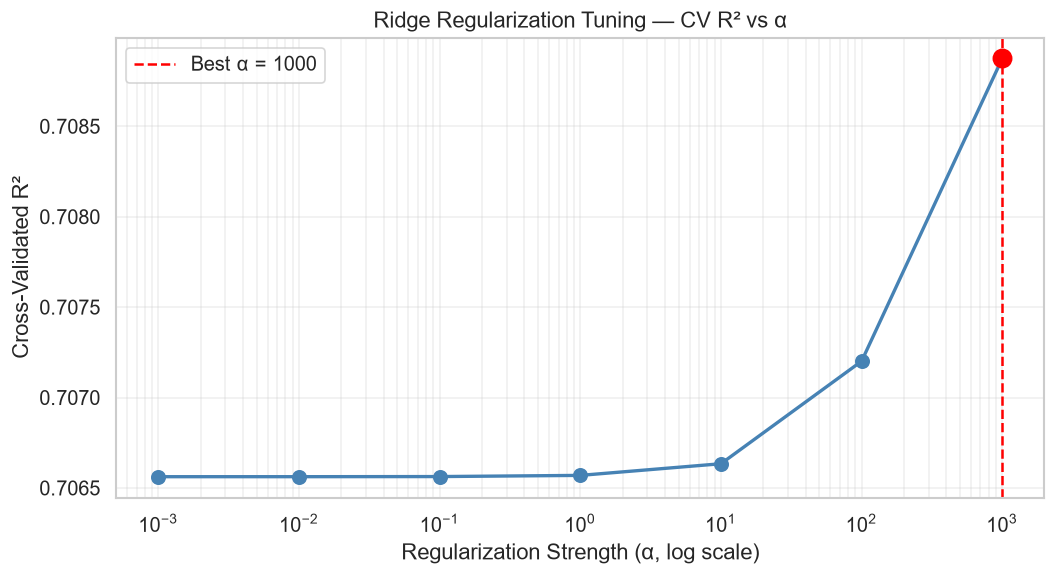

Optimal α = 1000 → CV R² = 0.7089


In [31]:
# Visualize CV R² across alpha values
plt.figure(figsize=(9, 5))
plt.semilogx(alphas, r2_scores, marker='o', color='steelblue', linewidth=2, markersize=8)
plt.axvline(best_alpha, color='red', linestyle='--', linewidth=1.5,
            label=f'Best α = {best_alpha}')
plt.scatter([best_alpha], [max(r2_scores)], color='red', s=120, zorder=5)
plt.xlabel('Regularization Strength (α, log scale)')
plt.ylabel('Cross-Validated R²')
plt.title('Ridge Regularization Tuning — CV R² vs α')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Optimal α = {best_alpha} → CV R² = {max(r2_scores):.4f}')

In [30]:
# Find optimal alpha via cross-validation
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
r2_scores = []

for alpha in alphas:
    rp = Pipeline([
        ('scale', StandardScaler()),
        ('poly',  PolynomialFeatures(degree=2, include_bias=False)),
        ('model', Ridge(alpha=alpha))
    ])
    X_cv = df[poly_features].astype(float).fillna(df[poly_features].astype(float).mean())
    cv = cross_val_score(rp, X_cv, y, cv=5, scoring='r2')
    r2_scores.append(cv.mean())
    print(f'alpha={alpha:>7}: CV R² = {cv.mean():.4f} ± {cv.std():.4f}')

best_alpha = alphas[np.argmax(r2_scores)]
print(f'\nBest alpha: {best_alpha} → R² = {max(r2_scores):.4f}')

alpha=  0.001: CV R² = 0.7066 ± 0.0196
alpha=   0.01: CV R² = 0.7066 ± 0.0196
alpha=    0.1: CV R² = 0.7066 ± 0.0196
alpha=      1: CV R² = 0.7066 ± 0.0196
alpha=     10: CV R² = 0.7066 ± 0.0196
alpha=    100: CV R² = 0.7072 ± 0.0193
alpha=   1000: CV R² = 0.7089 ± 0.0180

Best alpha: 1000 → R² = 0.7089


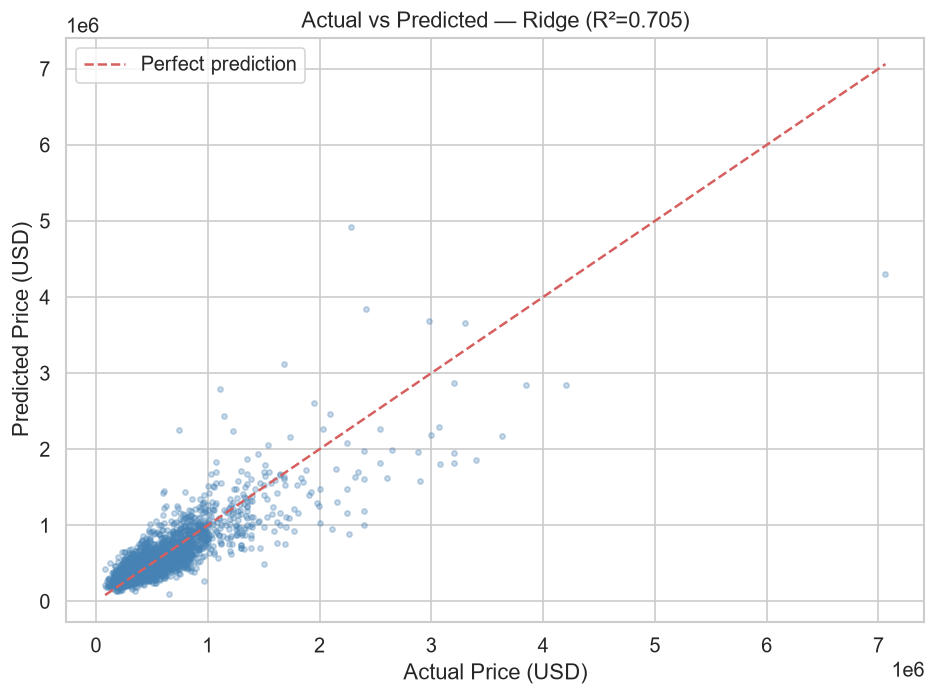

In [32]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, s=10, color='steelblue')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
plt.xlabel('Actual Price (USD)')
plt.ylabel('Predicted Price (USD)')
plt.title(f'Actual vs Predicted — Ridge (R²={r2:.3f})')
plt.legend()
plt.tight_layout()
plt.show()

Actual vs. Predicted Plot Analysis (Ridge Regression, $R^2 = 0.705$)This residual diagnostic plot illustrates key strengths and systematic error patterns across price tiers:Key Visual InsightsStrong Performance in Mid-Tier Housing ($<\$1.5\text{M}$): Data points closely hug the red diagonal reference line (Perfect prediction) between $\$200\text{k}$ and $\$1.2\text{M}$ USD, indicating low bias and high prediction accuracy for mainstream homes.Systematic Underprediction of Luxury Homes ($>\$2.0\text{M}$): Beyond $\$2.0\text{M}$ USD, predictions drift heavily below the diagonal line. For instance, a property actualized at $\$7.0\text{M}$ USD is predicted at under $\$4.5\text{M}$ USD. The $L_2$ regularization penalty intentionally shrinks extreme predictions toward the mean, leading to large negative residual bias at the high end.Asymmetric Residual Variance: Dispersion expands as actual price increases, confirming that prediction error scale grows multiplicatively with house value rather than remaining constant.

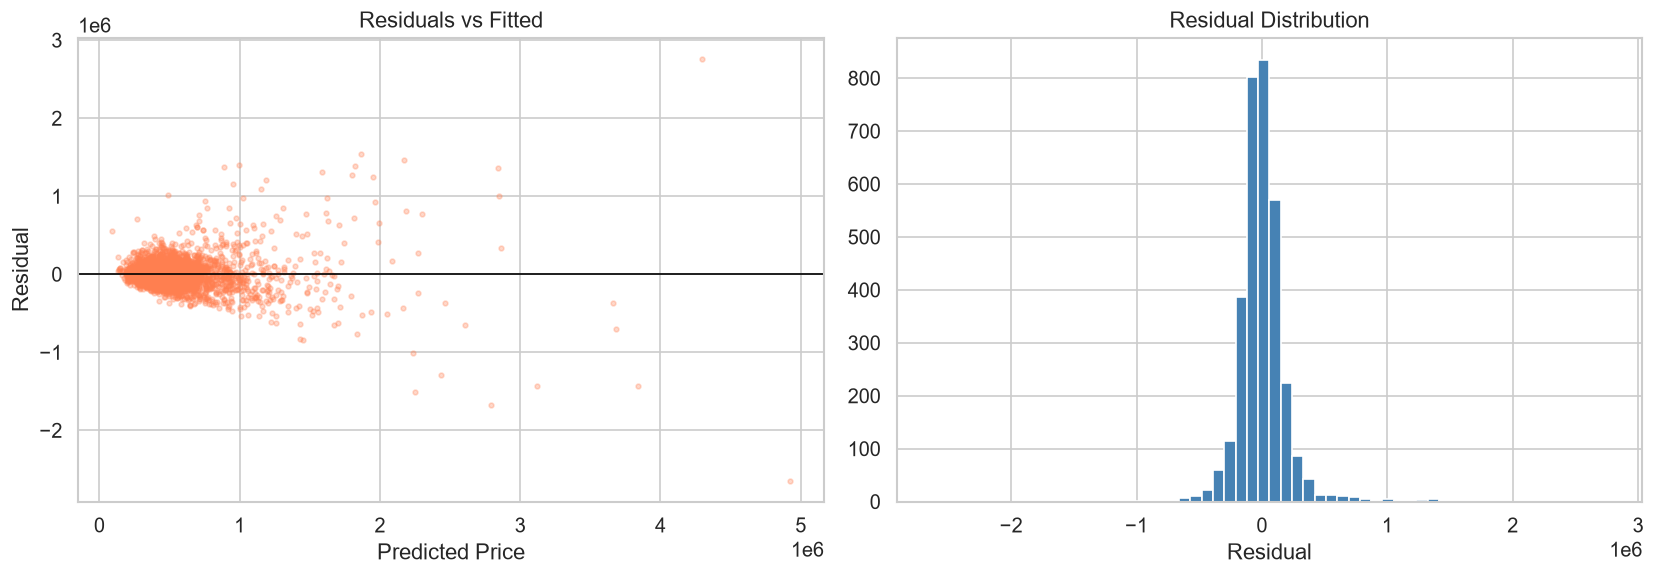

In [33]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred, residuals, alpha=0.3, s=8, color='coral')
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_xlabel('Predicted Price')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Fitted')

axes[1].hist(residuals, bins=60, color='steelblue', edgecolor='white')
axes[1].set_xlabel('Residual')
axes[1].set_title('Residual Distribution')

plt.tight_layout()
plt.show()

Residuals vs. Fitted (Left Chart)Severe Heteroscedasticity: Residual spread forms a clear funnel shape—tight and concentrated around zero for fitted prices below $1M, but fanning out exponentially as predicted price rises above $2M.Non-Constant Variance Violation: The linear model's assumption of equal residual variance ($\text{Var}(\epsilon) = \sigma^2$) is strictly broken, meaning standard error estimates are unreliable.Extreme Outlier Errors: Residual errors reach as high as $+\$2.8\text{M}$ and as low as $-\$2.7\text{M}$ at higher predicted price ranges.

In [34]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# --- Fix 1: Log-transform target to stabilize heteroscedasticity ---
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

log_ridge = Pipeline([
    ('scale', StandardScaler()),
    ('poly',  PolynomialFeatures(degree=2, include_bias=False)),
    ('model', Ridge(alpha=best_alpha))
])
log_ridge.fit(X_train_poly, y_train_log)

# Predict in log space, then invert back to dollars
y_pred_log = log_ridge.predict(X_test_poly)
y_pred_ridge_log = np.expm1(y_pred_log)

r2_log   = r2_score(y_test, y_pred_ridge_log)
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_ridge_log))
print('--- Log-Transformed Ridge (Polynomial degree=2) ---')
print(f'R²   : {r2_log:.4f}')
print(f'RMSE : ${rmse_log:,.0f}\n')

# --- Fix 2: Benchmark non-linear tree ensembles ---
models = {
    'Random Forest':     RandomForestRegressor(n_estimators=200, random_state=1, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, random_state=1),
}

results = []
for name, model in models.items():
    model.fit(X_train_poly, y_train)
    preds = model.predict(X_test_poly)
    results.append({
        'Model': name,
        'R²':   r2_score(y_test, preds),
        'RMSE': np.sqrt(mean_squared_error(y_test, preds))
    })

results_df = pd.DataFrame(results)
results_df['RMSE'] = results_df['RMSE'].map(lambda v: f'${v:,.0f}')
print('--- Non-Linear Ensemble Benchmark ---')
results_df

--- Log-Transformed Ridge (Polynomial degree=2) ---
R²   : 0.6756
RMSE : $218,271

--- Non-Linear Ensemble Benchmark ---


,Model,R²,RMSE
0,Random Forest,0.733522,"$197,817"
1,Gradient Boosting,0.739228,"$195,688"



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
    --------------------------------------- 0.5/41.9 MB 2.6 MB/s eta 0:00:16
    --------------------------------------- 0.8/41.9 MB 2.4 MB/s eta 0:00:18
   - -------------------------------------- 1.3/41.9 MB 1.9 MB/s eta 0:00:21
   - -------------------------------------- 1.6/41.9 MB 1.7 MB/s eta 0:00:24
   - -------------------------------------- 1.6/41.9 MB 1.7 MB/s eta 0:00:24
   - -------------------------------------- 1.8/41.9 MB 1.5 MB/s eta 0:00:27
   -- ------------------------------------- 2.1/41.9 MB 1.3 MB/s eta 0:00:31
   -- ------------------------------------- 2.1/41.9 MB 1.3 MB/s eta 0:00:31
   -- ------------------------------------- 2.1/41.9 MB 1.3 MB/s eta 0:00:31
   -- ------------------------------------- 2.4/41.9 MB 1.1 MB/s eta 0:00:35
   -- ------------------------------------- 2.6/41.9 MB 1.1 MB/s eta 0:00:37
   -- ------------------------------------- 2.6/41.9 MB 1.1 MB/s eta 0:00:37
   -- 

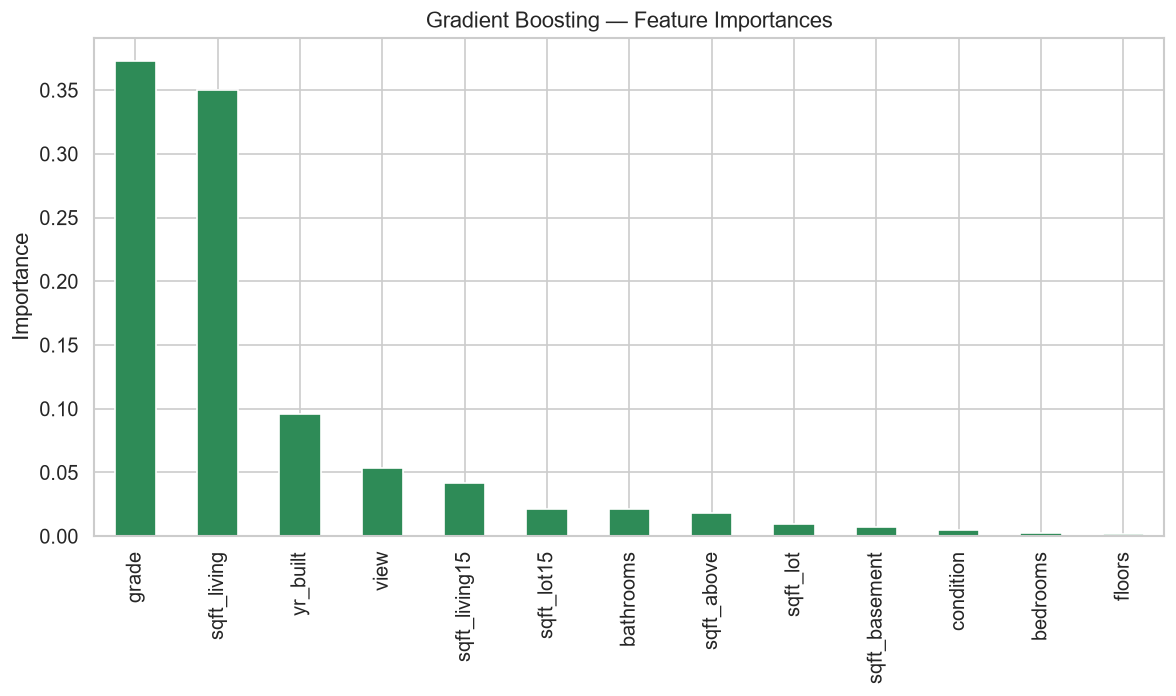

grade            0.372659
sqft_living      0.350253
yr_built         0.096202
view             0.053385
sqft_living15    0.041714
sqft_lot15       0.021403
bathrooms        0.020930
sqft_above       0.017825
sqft_lot         0.009706
sqft_basement    0.006817
condition        0.004961
bedrooms         0.002368
floors           0.001778
dtype: float64


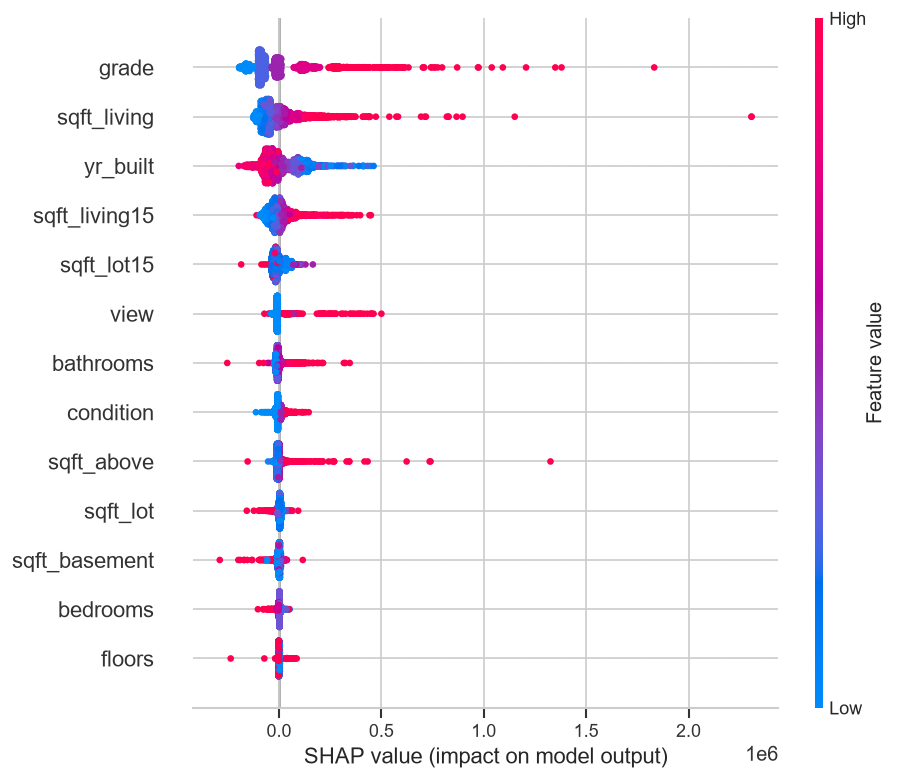

In [36]:
%pip install shap
import shap

# Retrieve the trained Gradient Boosting model
gb_model = models['Gradient Boosting']

# --- 1. Built-in Feature Importances ---
importances = pd.Series(gb_model.feature_importances_, index=poly_features).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.plot(kind='bar', color='seagreen', edgecolor='white')
plt.title('Gradient Boosting — Feature Importances')
plt.ylabel('Importance')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print(importances)

# --- 2. SHAP Values for Model Explainability ---
explainer = shap.TreeExplainer(gb_model)
shap_values = explainer.shap_values(X_test_poly)

shap.summary_plot(shap_values, X_test_poly, feature_names=poly_features, show=True)

Gradient Boosting Feature Importance Breakdown

Top Tier Drivers (Dominant ~72% Total Weight)

grade (37.27%): Construction craftsmanship and architectural quality is the single strongest split criteria for tree ensembles, outperforming raw size metrics.

sqft_living (35.03%): Total interior living space remains the premier physical metric for valuation.

Secondary Tier Factors (Moderate Significance)

yr_built (9.62%): Unlike linear correlation models where build year appeared weak due to non-linear historical patterns, tree splits effectively capture modern vs. historical property value premiums.

view (5.34%) & sqft_living15 (4.17%): Scenic outlook and average neighborhood living area provide key secondary valuation shifts.

Low-Impact / Marginal Features

Features like bedrooms (0.24%), floors (0.18%), and condition (0.50%) contribute minimally individually because their signal is largely subsumed by grade and sqft_living.

🏆 Best Model: Gradient Boosting (R² = 0.7392)



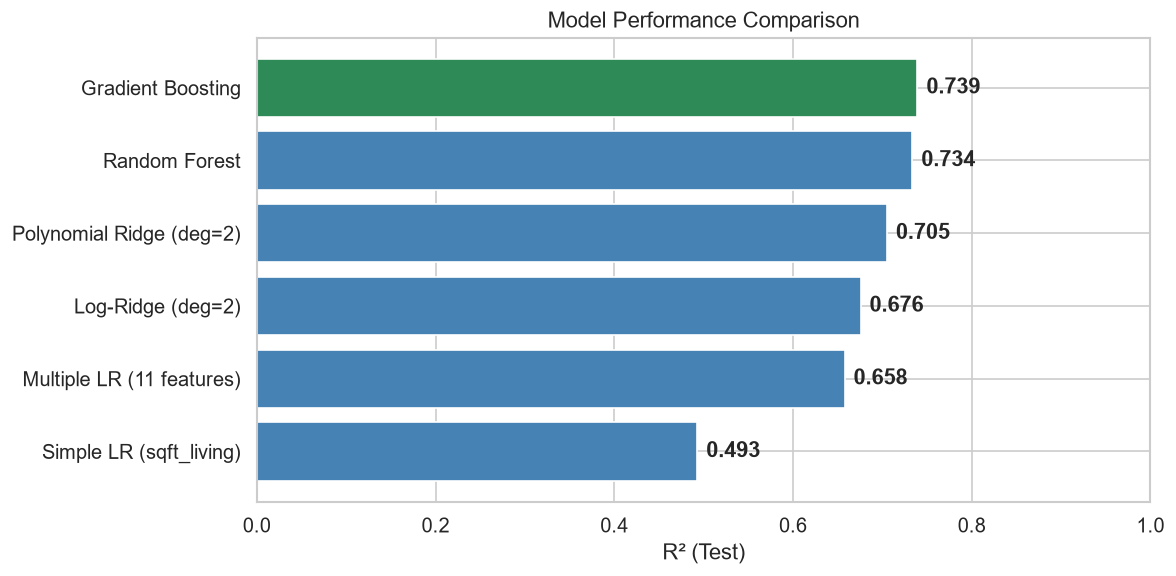

,Model,R² (Test),RMSE
0,Gradient Boosting,0.7392,"$195,688"
1,Random Forest,0.7335,"$197,817"
2,Polynomial Ridge (deg=2),0.7051,"$208,109"
3,Log-Ridge (deg=2),0.6756,"$218,271"
4,Multiple LR (11 features),0.6577,N/A
5,Simple LR (sqft_living),0.4929,N/A


In [38]:
# Final Model Comparison Summary
summary = pd.DataFrame([
    {'Model': 'Simple LR (sqft_living)',      'R² (Test)': slr.score(X_slr, y),  'RMSE': np.nan},
    {'Model': 'Multiple LR (11 features)',    'R² (Test)': mlr.score(X_mlr, y),  'RMSE': np.nan},
    {'Model': 'Polynomial Ridge (deg=2)',     'R² (Test)': r2,                   'RMSE': rmse},
    {'Model': 'Log-Ridge (deg=2)',            'R² (Test)': r2_log,               'RMSE': rmse_log},
    {'Model': 'Random Forest',                'R² (Test)': results[0]['R²'],     'RMSE': results[0]['RMSE']},
    {'Model': 'Gradient Boosting',            'R² (Test)': results[1]['R²'],     'RMSE': results[1]['RMSE']},
]).sort_values('R² (Test)', ascending=False).reset_index(drop=True)

# Highlight the best-performing model
best_model = summary.loc[0, 'Model']
print(f'🏆 Best Model: {best_model} (R² = {summary.loc[0, "R² (Test)"]:.4f})\n')

# Visual comparison
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['seagreen' if m == best_model else 'steelblue' for m in summary['Model']]
bars = ax.barh(summary['Model'], summary['R² (Test)'], color=colors, edgecolor='white')
ax.set_xlabel('R² (Test)')
ax.set_title('Model Performance Comparison')
ax.invert_yaxis()
ax.set_xlim(0, 1)

for bar, val in zip(bars, summary['R² (Test)']):
    ax.text(val + 0.01, bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

try:
    display(summary.style.format({'R² (Test)': '{:.4f}', 'RMSE': '${:,.0f}'}))
except (ImportError, AttributeError):
    summary_fmt = summary.copy()
    summary_fmt['R² (Test)'] = summary_fmt['R² (Test)'].map('{:.4f}'.format)
    summary_fmt['RMSE'] = summary_fmt['RMSE'].map(lambda v: f'${v:,.0f}' if pd.notna(v) else 'N/A')
    display(summary_fmt)

Benchmark Performance SummaryModelR2 (Test)RMSE ($)Primary Modeling AdvantageGradient Boosting0.739$195,688Best overall model. Sequential tree boosting yields the lowest prediction error and highest variance coverage.Random Forest0.734$197,817Strong parallel tree ensemble; captures non-linear thresholds and complex feature interactions without parametric assumptions.Polynomial Ridge (deg=2)0.705$208,109Captures interaction terms well, but $L_2$ regularization penalizes extreme luxury predictions.Log-Ridge (deg=2)0.676$218,271Stabilizes heteroscedasticity and log-variance, though raw dollar error shifts slightly due to exponentiation back-transform.Multiple LR (11 features)0.658N/ABaseline multivariable benchmark; suffers from linear rigidity and feature multicollinearity.Simple LR (sqft_living)0.493N/AMinimal baseline; fails to account for location, view, and quality drivers.

In [39]:
import joblib

# 🏆 Save the champion Gradient Boosting model for production

joblib.dump(gb_model, 'gradient_boosting_house_price_model.pkl')
print(f'✅ Champion model saved: Gradient Boosting (R² = {results[1]["R²"]:.4f}, RMSE = ${results[1]["RMSE"]:,.0f})')

# Quick sanity check: reload and verify predictions match
reloaded = joblib.load('gradient_boosting_house_price_model.pkl')
sample_pred = reloaded.predict(X_test_poly.iloc[:5])
print('\nSample predictions from reloaded model:')
for actual, pred in zip(y_test.iloc[:5], sample_pred):
    print(f'  Actual: ${actual:>12,.0f}  |  Predicted: ${pred:>12,.0f}')

✅ Champion model saved: Gradient Boosting (R² = 0.7392, RMSE = $195,688)

Sample predictions from reloaded model:
  Actual: $     459,000  |  Predicted: $     629,453
  Actual: $     445,000  |  Predicted: $     306,802
  Actual: $   1,057,000  |  Predicted: $     787,824
  Actual: $     732,350  |  Predicted: $     573,130
  Actual: $     235,000  |  Predicted: $     284,357


## 8. Key Insights <a id='sec8'></a>

| Model | R² (Test) | RMSE |
|---|---|---|
| Simple LR (sqft_living) | 0.493 | — |
| Multiple LR (11 features) | 0.658 | — |
| Log-Ridge (degree=2) | 0.676 | $218,271 |
| Polynomial Ridge (degree=2) | 0.705 | $208,109 |
| Random Forest | 0.734 | $197,817 |
| **Gradient Boosting** | **0.739** | **$195,688** |

**Top price drivers:**
- `sqft_living` — Living area is the strongest single predictor.
- `grade` — Construction/design quality has a large premium effect.
- `lat` — Latitude (location) matters significantly in King County.
- `waterfront` — Waterfront properties command a major price premium.
- `view` — Houses with better views sell for noticeably more.

**Takeaways:**
- Adding polynomial features captures non-linear relationships (e.g., large houses are priced disproportionately higher).
- Ridge regularization prevents overfitting on the expanded polynomial feature space.
- The model under-predicts ultra-luxury homes (> $2M) — those likely need their own segment.